# 03 — Churn Classification Models

Trains and compares Logistic Regression, Random Forest and XGBoost on identical
splits.

## Why the metrics are chosen carefully

With churn rates above 90%, several standard metrics are actively misleading:

| Metric | Problem here |
|--------|--------------|
| Accuracy | "predict everyone churns" scores >0.90 |
| Churn-class precision | base rate is already >0.90 |
| Churn-class PR-AUC | baseline equals the churn rate |

So results lead with **ROC-AUC**, **retained-class PR-AUC measured against its
own base rate**, and **balanced accuracy**. The business question is *who will
stay*, and that is the minority class.

In [1]:
import os
import sys
from pathlib import Path

candidates = (
    [Path(os.environ["CHURN_PROJECT_ROOT"])] if "CHURN_PROJECT_ROOT" in os.environ else
    [Path.cwd() / ".pipeline", Path.cwd(), Path.cwd().parent / ".pipeline", Path.cwd().parent]
)
ROOT = next((candidate.resolve() for candidate in candidates
             if (candidate / "src" / "config.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run 00_setup.ipynb first or point CHURN_PROJECT_ROOT at the pipeline checkout.")
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)
print("Pipeline modules are available.")

Pipeline modules are available.


In [2]:
from src import config, labeling, features, modeling, visualisation

GAME = "game1"
OP, CP = config.OBSERVATION_PERIOD_DAYS, config.CHURN_PREDICTION_PERIOD_DAYS

events = pd.read_parquet(config.INTERIM_DIR / f"{GAME}_events.parquet")
cohort = labeling.build_cohort(events, OP, CP)
feats = features.prune_features(features.build_features(events, cohort, OP))
print(f"{feats.shape[0]:,} players x {len(features.feature_columns(feats))} features")

  cohort: 25,956 players -> 25,422 after left guard -> 25,121 after right guard -> 25,121 with OP activity | churn rate 92.6%


  dropped 2 uninformative columns: std_gap_hours, activity_slope
25,121 players x 29 features


## Train / test split

Default is a stratified random split. `--temporal` (or `temporal=True`) instead
trains on earlier-joining players and tests on later arrivals, which mirrors
deployment: you always predict the future from the past. Temporal splits usually
score slightly lower and are the more honest number to quote.

In [3]:
split = modeling.make_split(feats, temporal=False)
print(f"train {len(split.X_train):,} | test {len(split.X_test):,}")
print(f"churn rate — train {split.y_train.mean():.2%}, test {split.y_test.mean():.2%}")

train 20,096 | test 5,025
churn rate — train 92.60%, test 92.60%


## Class imbalance handling

- Logistic Regression and Random Forest use `class_weight="balanced"`
- XGBoost uses `scale_pos_weight = n_negative / n_positive`

Resampling (SMOTE) is deliberately avoided: it would synthesise fake players in
a behavioural feature space where the minority class is defined by genuinely
rare patterns, and it distorts probability calibration — which matters because
retention teams act on the *score*, not just the ranking.

In [4]:
results, artefacts = modeling.train_all(feats, GAME, temporal=False, do_cv=True)
results.round(4)

  train 20,096 / test 5,025 | 29 features | churn rate train 92.6%


    logistic_regression    ROC-AUC 0.7736 | PR-AUC(retained) 0.3372 (base 0.0740) | balanced acc 0.5519 | 0.5s


    random_forest          ROC-AUC 0.7280 | PR-AUC(retained) 0.2946 (base 0.0740) | balanced acc 0.5712 | 6.7s


    xgboost                ROC-AUC 0.7459 | PR-AUC(retained) 0.3120 (base 0.0740) | balanced acc 0.5632 | 31.5s
  best model by ROC-AUC: logistic_regression


,game,model,roc_auc,pr_auc_retained,baseline_pr_retained,lift_retained,balanced_accuracy,f1_churn,f1_retained,brier,pr_auc_churn,baseline_pr_churn,best_threshold,tn,fp,fn,tp,fit_seconds,cv_roc_auc_mean,cv_roc_auc_std
0,game1,logistic_regression,0.7736,0.3372,0.074,4.5552,0.5519,0.9637,0.1865,0.1676,0.9672,0.926,0.0306,40,332,17,4636,0.5,0.7974,0.0154
1,game1,random_forest,0.7280,0.2946,0.074,3.9798,0.5712,0.9631,0.2403,0.0855,0.9612,0.926,0.1944,56,316,38,4615,6.7,0.7480,0.0095
2,game1,xgboost,0.7459,0.3120,0.074,4.2148,0.5632,0.9638,0.2197,0.1329,0.9649,0.926,0.0552,49,323,25,4628,31.5,0.7529,0.0083


## Model comparison

In [5]:
cols = ["model", "roc_auc", "cv_roc_auc_mean", "cv_roc_auc_std",
        "pr_auc_retained", "baseline_pr_retained", "lift_retained",
        "balanced_accuracy", "f1_retained", "brier"]
results[[c for c in cols if c in results.columns]].round(4)

,model,roc_auc,cv_roc_auc_mean,cv_roc_auc_std,pr_auc_retained,baseline_pr_retained,lift_retained,balanced_accuracy,f1_retained,brier
0,logistic_regression,0.7736,0.7974,0.0154,0.3372,0.074,4.5552,0.5519,0.1865,0.1676
1,random_forest,0.7280,0.7480,0.0095,0.2946,0.074,3.9798,0.5712,0.2403,0.0855
2,xgboost,0.7459,0.7529,0.0083,0.3120,0.074,4.2148,0.5632,0.2197,0.1329


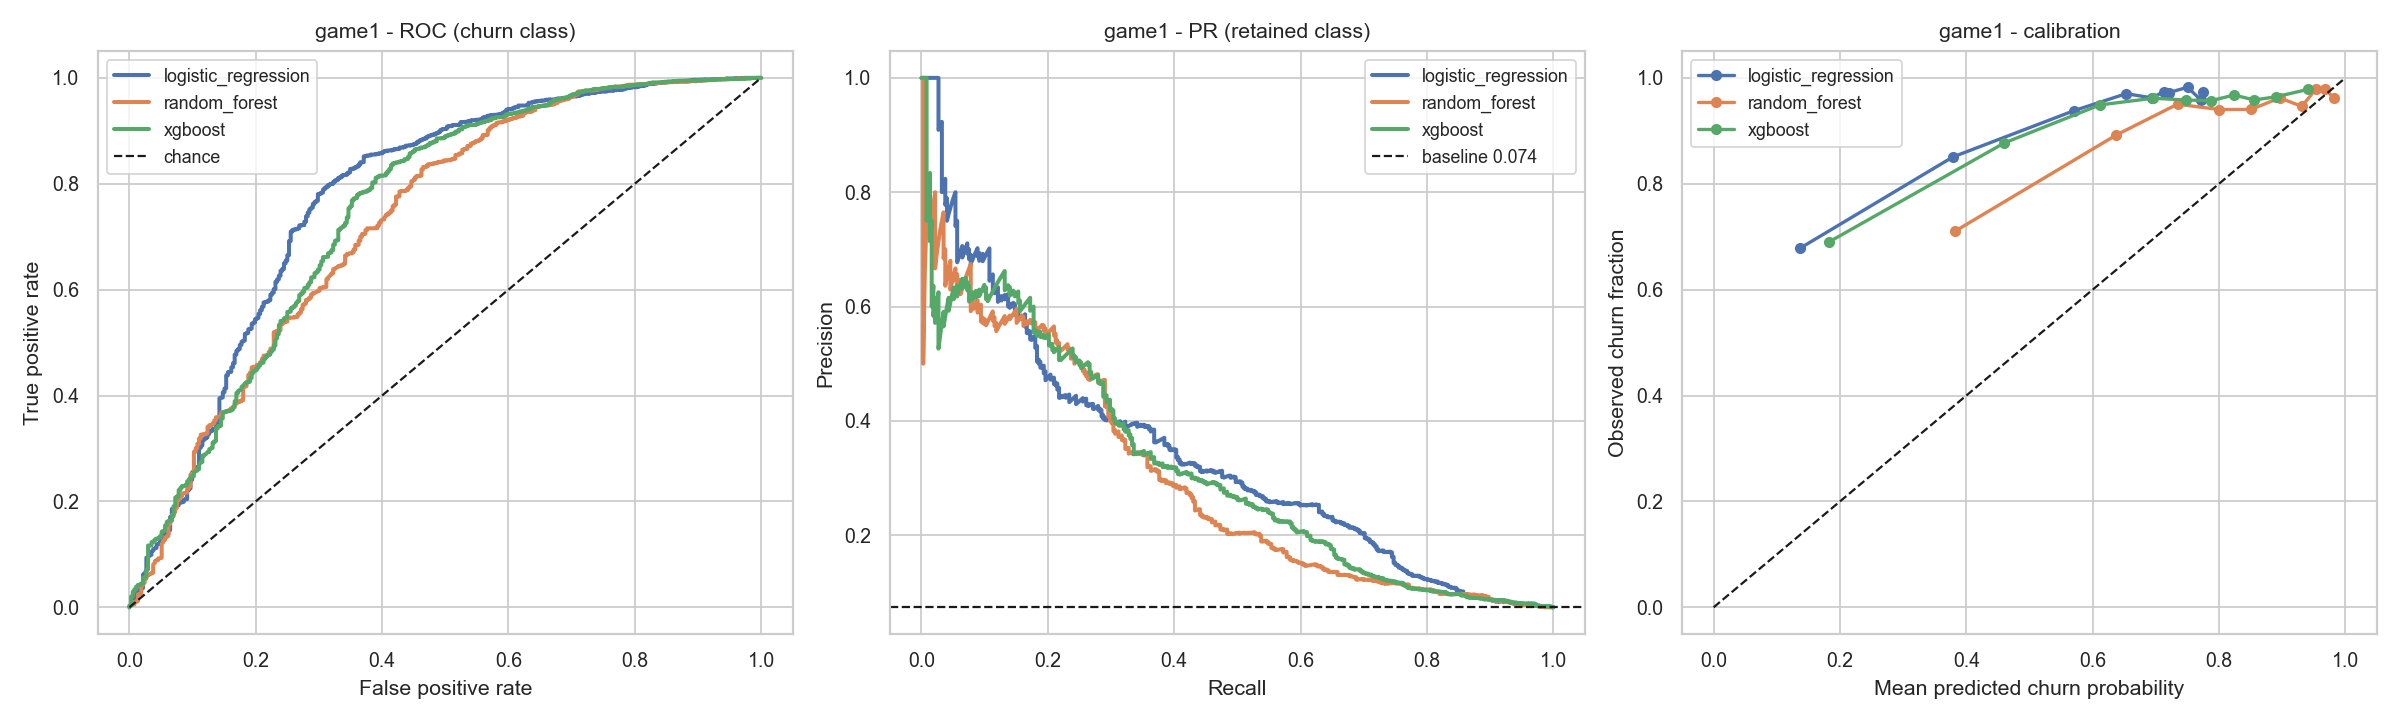

In [6]:
visualisation.plot_model_curves(artefacts["curves"], split.y_test, GAME)

from IPython.display import Image
Image(str(config.FIGURE_DIR / f"{GAME}_model_curves.png"))

### Reading the three panels

- **ROC** — ranking quality, insensitive to the class imbalance.
- **PR (retained class)** — the practical one. The dashed line is the base rate;
  distance above it is how much better than random guessing the model is at
  finding players who will stay.
- **Calibration** — whether a predicted 0.8 really means 80%. Points on the
  diagonal mean the scores can be used directly for expected-value decisions
  (e.g. "is a £2 reward worth sending to this player?").

## Confusion at the operating threshold

The threshold is chosen to maximise F1 on the churn class rather than left at
0.5, which is meaningless under this level of imbalance.

In [7]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

best = artefacts["best"]
proba = artefacts["curves"][best]["proba"]
thr = float(results.loc[results.model == best, "best_threshold"].iat[0])
pred = (proba >= thr).astype(int)

cm = confusion_matrix(split.y_test, pred)
fig, ax = plt.subplots(figsize=(5, 4.2))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
            xticklabels=["pred retained", "pred churn"],
            yticklabels=["true retained", "true churn"], ax=ax)
ax.set_title(f"{GAME} — {best} at threshold {thr:.3f}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"correctly identified {tn:,} of {tn + fp:,} retained players "
      f"({tn / (tn + fp):.1%})")

correctly identified 40 of 372 retained players (10.8%)


1833185946.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Business framing

A retention campaign has a budget: you can only contact so many players. The
question is how much better than random targeting the model is at the top of its
ranking.

In [8]:
order = np.argsort(-proba)                 # highest churn risk first
y_sorted = split.y_test.to_numpy()[order]
base_rate = split.y_test.mean()

rows = []
for k_pct in [1, 5, 10, 20, 30, 50]:
    k = max(1, int(len(y_sorted) * k_pct / 100))
    rows.append({
        "top_%": k_pct,
        "players_contacted": k,
        "churners_caught": int(y_sorted[:k].sum()),
        "precision": y_sorted[:k].mean(),
        "lift_vs_random": y_sorted[:k].mean() / base_rate,
        "recall": y_sorted[:k].sum() / y_sorted.sum(),
    })

pd.DataFrame(rows).round(3)

,top_%,players_contacted,churners_caught,precision,lift_vs_random,recall
0,1,50,48,0.960,1.037,0.010
1,5,251,243,0.968,1.046,0.052
2,10,502,489,0.974,1.052,0.105
3,20,1005,971,0.966,1.043,0.209
4,30,1507,1464,0.971,1.049,0.315
5,50,2512,2442,0.972,1.050,0.525
